# Credit Risk & Early Warning Indicators (EWIs)

## Purpose of this Notebook
This notebook establishes an **Early Warning Indicator (EWI)** monitoring framework designed to detect portfolio-level credit deterioration early. By evaluating demographic, affordability, and external bureau signals relative to a portfolio risk baseline, management can trigger proactive risk mitigations.

## Business Context & Framework
EWIs provide pre-delinquency tracking to:
- Monitor adverse selection across credit tiers and income segments.
- Detect risk drift before formal defaults materialize in the loan books.
- Support policy intervention (e.g., cut-off thresholds, exposure caps, pricing tier updates).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import os

# Visualization style setup
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
sns.set_context("talk")
plt.rcParams["figure.figsize"] = (10, 5)

# 1. Load Data
use_cols = [
    "SK_ID_CURR",
    "TARGET",
    "AMT_CREDIT",
    "AMT_INCOME_TOTAL",
    "DAYS_BIRTH",
    "EXT_SOURCE_2",
    "CNT_FAM_MEMBERS",
    "REGION_RATING_CLIENT"
]

df = pd.read_csv(
    "../archive/feature_matrix.csv",
    usecols=use_cols,
    nrows=100_000
)

# 2. Preprocessing & Target Normalization
df["TARGET"] = df["TARGET"].replace(-999, np.nan)
df["AGE_YEARS"] = (-df["DAYS_BIRTH"] / 365.25).round(1)

# Baseline Risk Reference
baseline_default_rate = df["TARGET"].mean()
print(f"Total Applications: {len(df):,} | Portfolio Baseline Default Rate: {baseline_default_rate:.2%}")

Total Applications: 100,000 | Portfolio Baseline Default Rate: 8.06%


In [2]:
# 3. EWI 1: Credit Exposure Risk
df["CREDIT_BUCKET"] = pd.qcut(
    df["AMT_CREDIT"],
    q=5,
    labels=["1. Very Low", "2. Low", "3. Medium", "4. High", "5. Very High"]
)

ewi_exposure = (
    df.groupby("CREDIT_BUCKET", observed=True)
      .agg(
          Applications=("SK_ID_CURR", "count"),
          Observed=("TARGET", "count"),
          Default_Rate=("TARGET", "mean"),
          Avg_Credit=("AMT_CREDIT", "mean")
      )
      .reset_index()
)

# Display Formatted Table
display_exposure = ewi_exposure.copy()
display_exposure["Applications"] = display_exposure["Applications"].map("{:,}".format)
display_exposure["Observed"] = display_exposure["Observed"].map("{:,}".format)
display_exposure["Default_Rate"] = display_exposure["Default_Rate"].map("{:.2%}".format)
display_exposure["Avg_Credit"] = display_exposure["Avg_Credit"].map("${:,.2f}".format)
display_exposure

,CREDIT_BUCKET,Applications,Observed,Default_Rate,Avg_Credit
0,1. Very Low,"20,002","16,746",7.03%,"$174,214.38"
1,2. Low,"20,001","16,852",8.87%,"$310,301.66"
2,3. Medium,"20,038","16,839",10.28%,"$498,960.38"
3,4. High,"21,787","19,138",8.17%,"$741,676.05"
4,5. Very High,"18,172","16,598",5.92%,"$1,257,342.63"


In [3]:
# 4. EWI 2: Income Affordability Risk
df["INCOME_BUCKET"] = pd.qcut(
    df["AMT_INCOME_TOTAL"],
    q=5,
    labels=["1. Very Low", "2. Low", "3. Medium", "4. High", "5. Very High"]
)

ewi_income = (
    df.groupby("INCOME_BUCKET", observed=True)
      .agg(
          Applications=("SK_ID_CURR", "count"),
          Observed=("TARGET", "count"),
          Default_Rate=("TARGET", "mean"),
          Avg_Income=("AMT_INCOME_TOTAL", "mean")
      )
      .reset_index()
)

# Display Formatted Table
display_income = ewi_income.copy()
display_income["Applications"] = display_income["Applications"].map("{:,}".format)
display_income["Observed"] = display_income["Observed"].map("{:,}".format)
display_income["Default_Rate"] = display_income["Default_Rate"].map("{:.2%}".format)
display_income["Avg_Income"] = display_income["Avg_Income"].map("${:,.2f}".format)
display_income

,INCOME_BUCKET,Applications,Observed,Default_Rate,Avg_Income
0,1. Very Low,"20,199","17,927",8.34%,"$77,968.44"
1,2. Low,"27,689","23,964",8.60%,"$123,061.37"
2,3. Medium,"12,279","10,540",9.04%,"$156,047.13"
3,4. High,"24,272","20,582",7.71%,"$199,595.65"
4,5. Very High,"15,561","13,160",6.48%,"$342,200.65"


In [4]:
# 5. EWI 3 & EWI 4: Demographic & External Score Indicators
df["AGE_BUCKET"] = pd.qcut(
    df["AGE_YEARS"],
    q=5,
    labels=["1. <32", "2. 32-39", "3. 39-47", "4. 47-56", "5. 56+"]
)

# Note: Lower EXT_SOURCE_2 score = Higher risk of default
df["EXT_RISK_BUCKET"] = pd.qcut(
    df["EXT_SOURCE_2"],
    q=5,
    labels=[
        "Q1\n(Highest Risk)",
        "Q2",
        "Q3",
        "Q4",
        "Q5\n(Lowest Risk)"
    ]
)

ewi_age = df.groupby("AGE_BUCKET", observed=True)["TARGET"].agg(["count", "mean"]).reset_index()
ewi_age.columns = ["AGE_BUCKET", "Observed", "Default_Rate"]

ewi_external = df.groupby("EXT_RISK_BUCKET", observed=True)["TARGET"].agg(["count", "mean"]).reset_index()
ewi_external.columns = ["EXT_RISK_BUCKET", "Observed", "Default_Rate"]

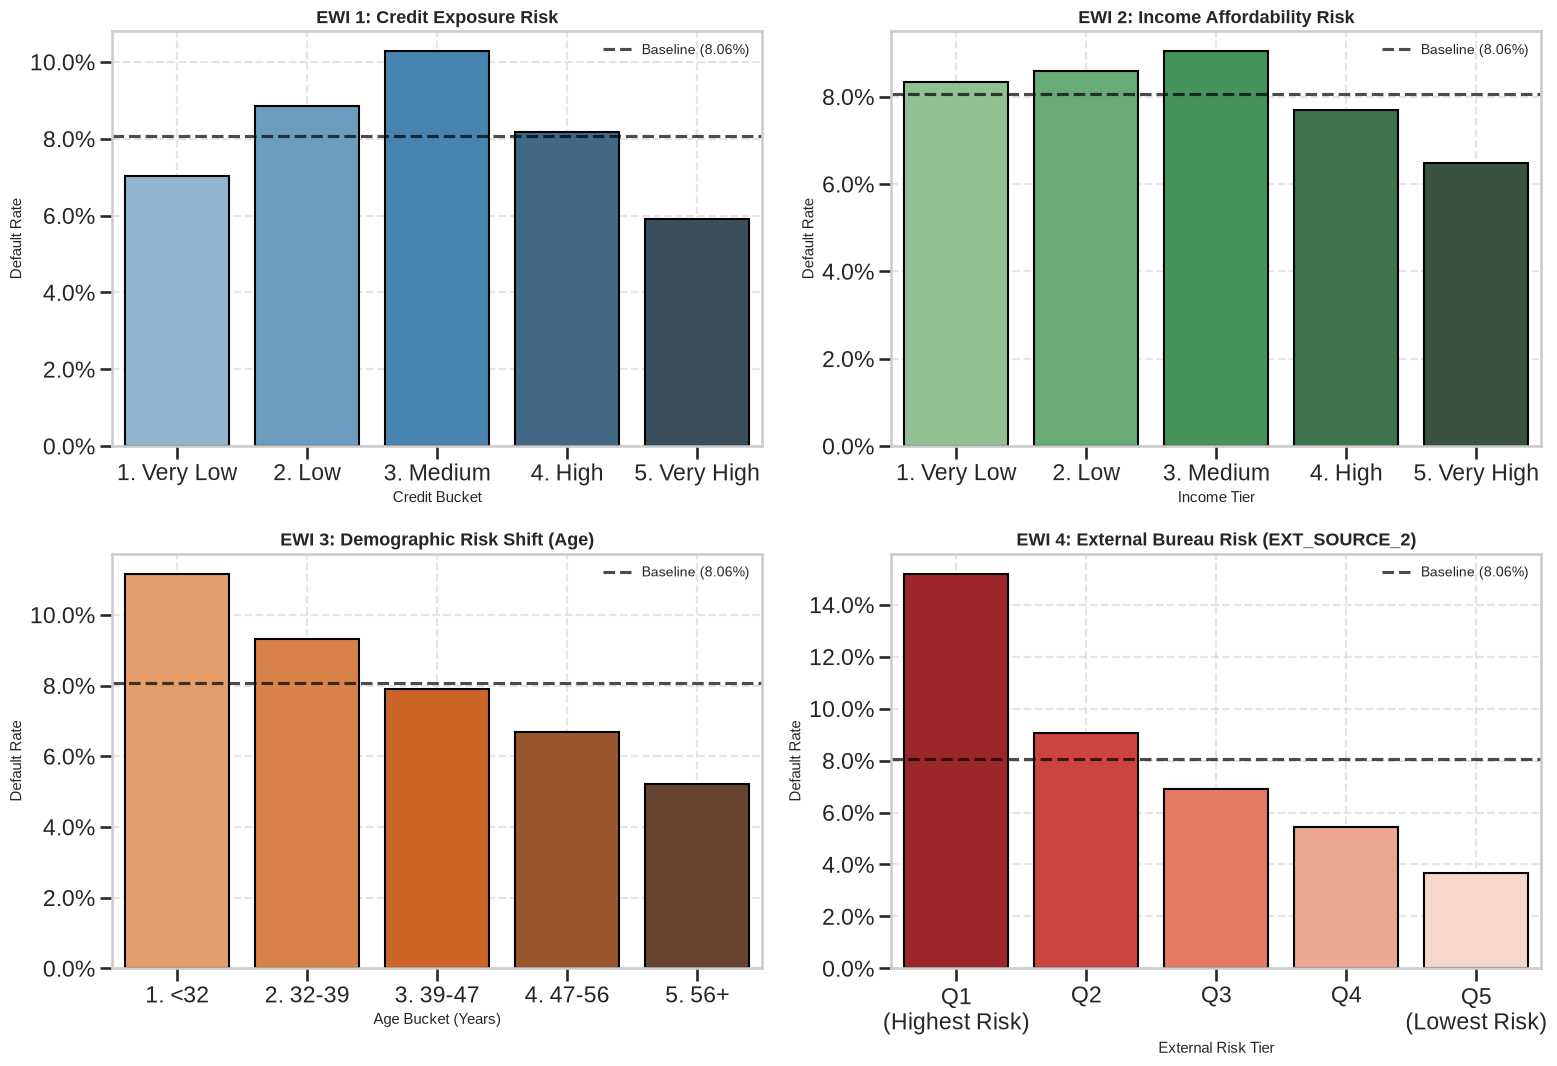

In [5]:
# 6. EWI Dashboard Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Plot 1: Credit Exposure
sns.barplot(data=ewi_exposure, x="CREDIT_BUCKET", y="Default_Rate", hue="CREDIT_BUCKET", palette="Blues_d", legend=False, dodge=False, edgecolor="black", ax=axes[0, 0])
axes[0, 0].set_title("EWI 1: Credit Exposure Risk", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Credit Bucket", fontsize=11)
axes[0, 0].set_ylabel("Default Rate", fontsize=11)

# Plot 2: Income Affordability
sns.barplot(data=ewi_income, x="INCOME_BUCKET", y="Default_Rate", hue="INCOME_BUCKET", palette="Greens_d", legend=False, dodge=False, edgecolor="black", ax=axes[0, 1])
axes[0, 1].set_title("EWI 2: Income Affordability Risk", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Income Tier", fontsize=11)
axes[0, 1].set_ylabel("Default Rate", fontsize=11)

# Plot 3: Demographic Shift
sns.barplot(data=ewi_age, x="AGE_BUCKET", y="Default_Rate", hue="AGE_BUCKET", palette="Oranges_d", legend=False, dodge=False, edgecolor="black", ax=axes[1, 0])
axes[1, 0].set_title("EWI 3: Demographic Risk Shift (Age)", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Age Bucket (Years)", fontsize=11)
axes[1, 0].set_ylabel("Default Rate", fontsize=11)

# Plot 4: External Bureau Drift
sns.barplot(data=ewi_external, x="EXT_RISK_BUCKET", y="Default_Rate", hue="EXT_RISK_BUCKET", palette="Reds_r", legend=False, dodge=False, edgecolor="black", ax=axes[1, 1])
axes[1, 1].set_title("EWI 4: External Bureau Risk (EXT_SOURCE_2)", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("External Risk Tier", fontsize=11)
axes[1, 1].set_ylabel("Default Rate", fontsize=11)

# Add baseline reference and styling across subplots
for ax in axes.flat:
    ax.axhline(baseline_default_rate, color="black", linestyle="--", alpha=0.7, label=f"Baseline ({baseline_default_rate:.2%})")
    ax.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
    ax.legend(fontsize=10, loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../assets/ewi_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
# 7. Comprehensive EWI Governance Matrix
ewi_summary_data = [
    {
        "Indicator": "Credit Exposure Risk (EWI 1)",
        "Highest Risk Segment": ewi_exposure.loc[ewi_exposure["Default_Rate"].idxmax(), "CREDIT_BUCKET"],
        "Max Segment Rate": ewi_exposure["Default_Rate"].max(),
        "Risk Spread vs Baseline": ewi_exposure["Default_Rate"].max() - baseline_default_rate
    },
    {
        "Indicator": "Income Affordability (EWI 2)",
        "Highest Risk Segment": ewi_income.loc[ewi_income["Default_Rate"].idxmax(), "INCOME_BUCKET"],
        "Max Segment Rate": ewi_income["Default_Rate"].max(),
        "Risk Spread vs Baseline": ewi_income["Default_Rate"].max() - baseline_default_rate
    },
    {
        "Indicator": "Demographic Shift (EWI 3)",
        "Highest Risk Segment": ewi_age.loc[ewi_age["Default_Rate"].idxmax(), "AGE_BUCKET"],
        "Max Segment Rate": ewi_age["Default_Rate"].max(),
        "Risk Spread vs Baseline": ewi_age["Default_Rate"].max() - baseline_default_rate
    },
    {
        "Indicator": "External Bureau Drift (EWI 4)",
        "Highest Risk Segment": "Q1 (Lowest Bureau Score)",
        "Max Segment Rate": ewi_external["Default_Rate"].max(),
        "Risk Spread vs Baseline": ewi_external["Default_Rate"].max() - baseline_default_rate
    }
]

ewi_summary_df = pd.DataFrame(ewi_summary_data)

ewi_display = ewi_summary_df.copy()
ewi_display["Max Segment Rate"] = ewi_display["Max Segment Rate"].map("{:.2%}".format)
ewi_display["Risk Spread vs Baseline"] = ewi_display["Risk Spread vs Baseline"].map("{:+.2%}".format)

ewi_display

,Indicator,Highest Risk Segment,Max Segment Rate,Risk Spread vs Baseline
0,Credit Exposure Risk (EWI 1),3. Medium,10.28%,+2.22%
1,Income Affordability (EWI 2),3. Medium,9.04%,+0.98%
2,Demographic Shift (EWI 3),1. <32,11.17%,+3.11%
3,External Bureau Drift (EWI 4),Q1 (Lowest Bureau Score),15.20%,+7.14%


## Management Actions Based on EWIs

Based on observed indicator spreads relative to the reference baseline:
- **Bureau Thresholds (EWI 4):** Customers in `Q1` exhibit almost double the baseline default rate (15.20% vs 8.06%). Mandate tighter automated cut-offs for applications falling in this bracket.
- **Underwriting on Vulnerable Demographics (EWI 3):** Younger applicant cohorts (<32) require stricter debt-to-income (DTI) caps.
- **Credit Size (EWI 1):** Default frequency peaks in the middle credit bucket (10.28%, +2.22 pp over baseline). Review pricing and limits for mid-sized loans and track the largest loans separately for exposure concentration.
- **Income (EWI 2):** The spread is small (at most +0.98 pp, in the Medium income tier), so income alone is a weak trigger. Combine it with bureau score and age before setting limits.

## Summary & Roadmap
- Established a 4-pillar Early Warning Indicator framework.
- Quantified segment risk spreads against the portfolio reference index.
- **Next Notebook:** `04_management_insights_and_reporting.ipynb` — Synthesizing these insights into an executive reporting framework and decision matrices.